# 01 Data exploration

Exploratory analysis of the French motor third-party liability data (`freMTPL2freq` / `freMTPL2sev`, CASdatasets). **Only the training split is explored** so that nothing learned here leaks from validation or test data.

Run `python -m scripts.prepare_data` first.

In [1]:
import sys, warnings
sys.path.insert(0, "..")            # make the project's src/ package importable from notebooks/
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils.config import ROOT, load_config
cfg = load_config()
proc = ROOT / cfg["paths"]["processed_dir"]
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
train = pd.read_parquet(proc / "policies_train.parquet")
claims = pd.read_parquet(proc / "severity_claims.parquet")
claims = claims[claims["IDpol"].isin(train["IDpol"])]
print(f"{len(train):,} training policies, {len(claims):,} training claims")
train.head()

406,794 training policies, 15,872 training claims


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region,TotalClaimAmount
0,6056117,0.0,0.43,7,10,42,50,B1,Diesel,E,3541,Pays-de-la-Loire,0.00
1,4162729,0.0,0.77,7,18,34,60,B2,Diesel,A,25,Centre,0.00
2,3254356,0.0,0.01,4,13,39,57,B2,Regular,E,4059,Haute-Normandie,0.00
3,1122657,1.0,0.22,7,13,74,77,B1,Regular,D,1601,Lorraine,1488.08
4,2064364,0.0,1.00,8,1,63,50,B2,Diesel,D,741,Centre,0.00


## Data quality
The quality report was computed on the full raw files during preparation (no missing values, no duplicate ids; exposure above 1 year is capped at 1; claim counts match the severity rows).

In [2]:
import json
print(json.dumps(json.loads((proc / "quality_report.json").read_text()), indent=1))

{
 "n_policies": 677991,
 "n_severity_rows": 26444,
 "duplicate_policy_ids": 0,
 "missing_values": 0,
 "exposure_gt_1": 1224,
 "sev_ids_not_in_freq": 0,
 "policies_with_claims": 24944,
 "policies_with_sev_rows": 24944,
 "claimnb_ne_sev_rows": 0,
 "claimnb_gt0_without_sev": 0,
 "sev_rows_for_zero_claimnb": 0
}


## Exposure, claim counts and severity
**Pricing meaning:** exposure varies a lot (many partial-year policies), so frequency must be modelled per exposure-year, not per policy. About 96% of policies have no claim, and severity is extremely heavy-tailed.

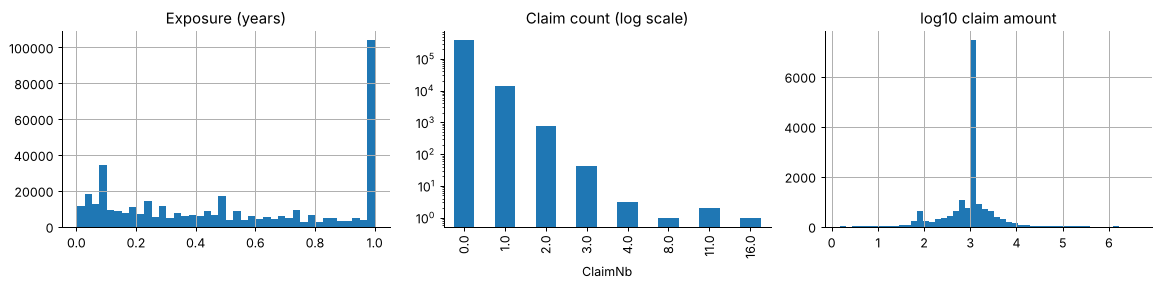

zero-claim share 0.963; mean 0.0390, variance 0.0433, var/mean 1.11
frequency per exposure-year 0.0738
severity median 1,172, p99 16,790, p99.9 156,057, max 4,075,401
top 0.1% of claims = 25.9% of total claim amount


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
train["Exposure"].hist(bins=40, ax=ax[0]); ax[0].set_title("Exposure (years)")
train["ClaimNb"].value_counts().sort_index().plot.bar(ax=ax[1], logy=True); ax[1].set_title("Claim count (log scale)")
np.log10(claims["ClaimAmount"]).hist(bins=50, ax=ax[2]); ax[2].set_title("log10 claim amount")
plt.tight_layout(); plt.show()
m, v = train["ClaimNb"].mean(), train["ClaimNb"].var()
print(f"zero-claim share {(train.ClaimNb == 0).mean():.3f}; mean {m:.4f}, variance {v:.4f}, var/mean {v/m:.2f}")
print(f"frequency per exposure-year {train.ClaimNb.sum() / train.Exposure.sum():.4f}")
q = claims["ClaimAmount"].quantile([.5, .9, .99, .999])
top = claims["ClaimAmount"].nlargest(max(1, int(0.001 * len(claims)))).sum() / claims["ClaimAmount"].sum()
print(f"severity median {q[.5]:,.0f}, p99 {q[.99]:,.0f}, p99.9 {q[.999]:,.0f}, max {claims.ClaimAmount.max():,.0f}")
print(f"top 0.1% of claims = {top:.1%} of total claim amount")

**Reading this:** the raw variance/mean of counts (about 1.1) ignores exposure and covariates, so it understates overdispersion; the fitted Poisson GLM in notebook 02 gives a Pearson dispersion near 1.9. The top 0.1% of claims carry roughly a quarter of all claim cost, which is why severity and the expected-cost level are hard to estimate.

## Frequency by risk factor (training data)

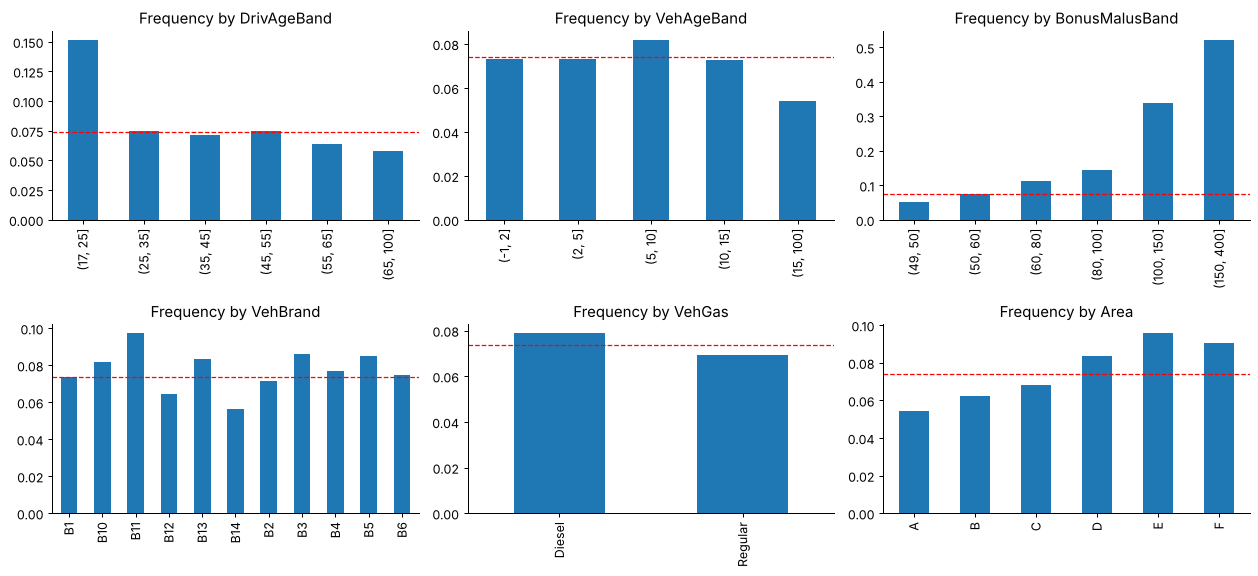

In [4]:
t = train.assign(
    DrivAgeBand=pd.cut(train.DrivAge, [17, 25, 35, 45, 55, 65, 100]),
    VehAgeBand=pd.cut(train.VehAge, [-1, 2, 5, 10, 15, 100]),
    BonusMalusBand=pd.cut(train.BonusMalus, [49, 50, 60, 80, 100, 150, 400]))
overall = train.ClaimNb.sum() / train.Exposure.sum()
cols = ["DrivAgeBand", "VehAgeBand", "BonusMalusBand", "VehBrand", "VehGas", "Area"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for a, c in zip(axes.ravel(), cols):
    g = t.groupby(c, observed=True).agg(claims=("ClaimNb", "sum"), exposure=("Exposure", "sum"))
    (g.claims / g.exposure).plot.bar(ax=a); a.axhline(overall, color="r", ls="--", lw=1); a.set_title(f"Frequency by {c}"); a.set_xlabel("")
plt.tight_layout(); plt.show()

**Pricing meaning:** claim frequency rises sharply for young drivers and for high bonus-malus (malus) policies, and varies with vehicle and area. These are associations in observational data, not causal effects. Bonus-malus and driver age partly proxy for each other.

## Train / validation / test comparability
The split is a stratified random split by policy (the data has no date column, so an out-of-time holdout is impossible). To check the splits look alike, only the **risk features** of validation and test are inspected below. Their claim outcomes are not read in this notebook.

In [5]:
feats = ["Exposure", "DrivAge", "VehAge", "BonusMalus", "Density"]       # features only: no ClaimNb / claim amounts
rows = []
for n in ("train", "val", "test"):
    d = pd.read_parquet(proc / f"policies_{n}.parquet", columns=feats)
    rows.append({"split": n, "policies": len(d), **d.mean().add_prefix("mean_").to_dict()})
pd.DataFrame(rows).round(3)

,split,policies,mean_Exposure,mean_DrivAge,mean_VehAge,mean_BonusMalus,mean_Density
0,train,406794,0.528,45.505,7.050,59.775,1788.190
1,val,135598,0.529,45.501,7.053,59.735,1787.998
2,test,135599,0.528,45.480,7.017,59.748,1809.466


**Reading this:** the average exposure, driver age, vehicle age, bonus-malus and density are essentially identical across the three splits, as expected from a random split of one population, so train and test are comparable in their inputs.